# 04 — Quantização Pós-Treinamento (ONNX / INT8) e Benchmark de Inferência em CPU (Etapa 4)

Este notebook documenta e reproduz a **Etapa 4** do **ArborGrid Vision**:
1. **Desafios de Quantização em Vision Transformers (SegFormer-B2)**: Por que a quantização **INT8 Estática (QDQ)** degrada severamente a segmentação de estruturas sub-pixel (`IoU Fiação = 21,95%`) devido aos *outliers* assimétricos pós-`GELU` nos blocos *Mix-FFN*.
2. **A Solução Vencedora (`ONNX INT8 Dinâmico — MatMulInteger`)**: Como a quantização dinâmica restrita aos operadores `MatMul` comprime o modelo em **-50,4%** (`104,49 MiB -> 51,77 MiB` — compatível com o limite de 100 MB do GitHub puro), acelera a inferência em CPU e preserva **98,46% da fidelidade de máscara de fiação**.
3. **Validação ao Vivo (`PyTorch FP32` vs `ONNX Runtime INT8`)**: Comparação visual e numérica direta executando `models/segformer_v3_int8_dyn_matmul.onnx` lado a lado com o modelo PyTorch original.

In [1]:
import json
import sys
import time
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

BASE_DIR = Path.cwd()
if str(BASE_DIR / "scripts") not in sys.path:
    sys.path.insert(0, str(BASE_DIR / "scripts"))

from vision_utils import (
    infer_masks,
    load_onnx_session,
    load_segformer_weights,
    render_diff_panel,
    render_overlay,
    stamp_header,
)

REPORTS_DIR = BASE_DIR / "reports"
MODELS_DIR = BASE_DIR / "models"
WS_DIR = BASE_DIR / "dataset" / "workspace_xanylabeling"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

## 1. Benchmark Comparativo das 6 Variantes de Exportação e Quantização (`etapa4_quantization_benchmark_report.json`)

In [2]:
q_report = json.loads((REPORTS_DIR / "etapa4_quantization_benchmark_report.json").read_text(encoding="utf-8"))

VARIANT_LABELS = {
    "pytorch_fp32": "PyTorch FP32 (Baseline)",
    "onnx_fp32": "ONNX FP32",
    "onnx_fp16": "ONNX FP16",
    "onnx_int8_dyn_matmul": "ONNX INT8 Dinâmico (MatMul)",
    "onnx_int8_dynamic": "ONNX INT8 Dinâmico (Full)",
    "onnx_int8_static_qdq": "ONNX INT8 Estático (QDQ)",
}
rows_q = []
for v in q_report:
    gt_m = v.get("val_metrics", {})
    lat_ms = float(v["latency_mean_ms"])
    rows_q.append({
        "Variante / Formato": VARIANT_LABELS.get(v["variant"], v["variant"]),
        "Tamanho Disco (MiB)": round(v["size_mib"], 2),
        "Redução (%)": round((1.0 - v["size_mib"] / 104.49) * 100, 1),
        "Latência CPU (ms/img)": round(lat_ms, 1),
        "Throughput (FPS)": round(1000.0 / lat_ms, 3),
        "IoU Copa vs GT (%)": round(gt_m.get("copa_iou", 0), 2),
        "IoU Fiação vs GT (%)": round(gt_m.get("fiacao_iou", 0), 2),
        "Precision Fiação (%)": round(gt_m.get("fiacao_precision", 0), 2),
        "Acordo Triagem vs FP32 (%)": round(v.get("triage_agreement_pct", 0), 2),
    })

df_quant = pd.DataFrame(rows_q)
display(df_quant)

Variante / Formato,Tamanho Disco (MiB),Redução (%),Latência CPU (ms/img),Throughput (FPS),IoU Copa vs GT (%),IoU Fiação vs GT (%),Precision Fiação (%),Acordo Triagem vs FP32 (%)
PyTorch FP32 (Baseline),104.49,0.0,4401.1,0.227,92.86,42.44,76.59,100.00
ONNX FP32,104.59,-0.1,2732.5,0.366,92.86,42.44,76.59,100.00
ONNX FP16,52.53,49.7,3376.8,0.296,92.86,42.44,76.59,100.00
ONNX INT8 Dinâmico (MatMul),51.77,50.5,2478.9,0.403,92.89,42.55,75.05,100.00
ONNX INT8 Dinâmico (Full),26.87,74.3,26643.1,0.038,92.88,42.40,74.93,96.43
ONNX INT8 Estático (QDQ),27.38,73.8,5944.7,0.168,91.05,40.41,78.01,92.86


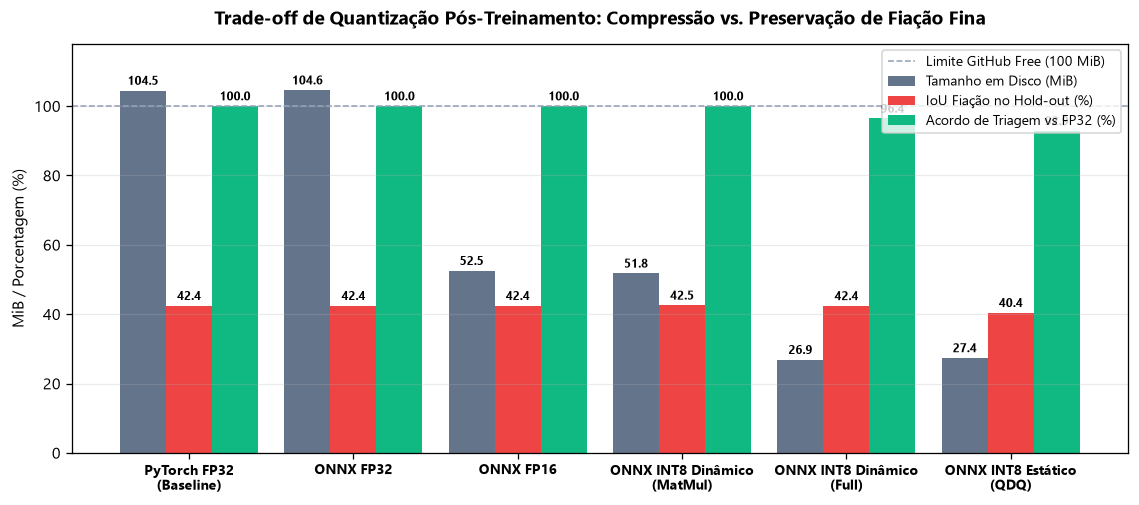

In [3]:
# Gráfico Trade-off: Tamanho em Disco (MiB) vs IoU Fiação (%) vs Acordo de Triagem (%)
_, ax1 = plt.subplots(figsize=(10, 4.5))
names = [r["Variante / Formato"].replace(" (", "\n(") for r in rows_q]
x = np.arange(len(names))
w = 0.28

b1 = ax1.bar(x - w, df_quant["Tamanho Disco (MiB)"], width=w, label="Tamanho em Disco (MiB)", color="#64748b")
b2 = ax1.bar(x, df_quant["IoU Fiação vs GT (%)"], width=w, label="IoU Fiação no Hold-out (%)", color="#ef4444")
b3 = ax1.bar(x + w, df_quant["Acordo Triagem vs FP32 (%)"], width=w, label="Acordo de Triagem vs FP32 (%)", color="#10b981")

ax1.axhline(100.0, color="#94a3b8", linestyle="--", linewidth=1, label="Limite GitHub Free (100 MiB)")
ax1.set_xticks(x)
ax1.set_xticklabels(names, fontsize=8.5, fontweight="bold")
ax1.set_ylim(0, 118)
ax1.set_ylabel("MiB / Porcentagem (%)")
ax1.set_title("Trade-off de Quantização Pós-Treinamento: Compressão vs. Preservação de Fiação Fina", fontweight="bold", pad=12)
ax1.legend(loc="upper right", frameon=True, fontsize=8.5)
ax1.grid(axis="y", alpha=0.25)

for bar in list(b1) + list(b2) + list(b3):
    val = bar.get_height()
    ax1.annotate(f"{val:.1f}", (bar.get_x() + bar.get_width() / 2, val), xytext=(0, 2),
                 textcoords="offset points", ha="center", va="bottom", fontsize=7.5, fontweight="bold")

plt.tight_layout()
plt.show()

## 2. Teste de Inferência Real ao Vivo: `PyTorch FP32` vs `ONNX Runtime INT8 (MatMulInteger)`

Carregamos abaixo o arquivo `models/segformer_v3_int8_dyn_matmul.onnx` (51,8 MiB, versionado diretamente no Git) no **ONNX Runtime CPU** e comparamos sua máscara pixel a pixel contra o checkpoint **PyTorch FP32 (`arborgrid_segformer_b2_1024_v3_gold.pt`)**:

Fidelidade ONNX INT8 vs PyTorch FP32 na amostra #tree_1001772_center_front_h234:
  -> IoU Copa Arbórea : 98.96% | IoU Fiação Aérea: 90.27%
  -> Tempo PyTorch (CUDA): 163.0 ms | Tempo ONNX INT8 (CPU): 1694.4 ms


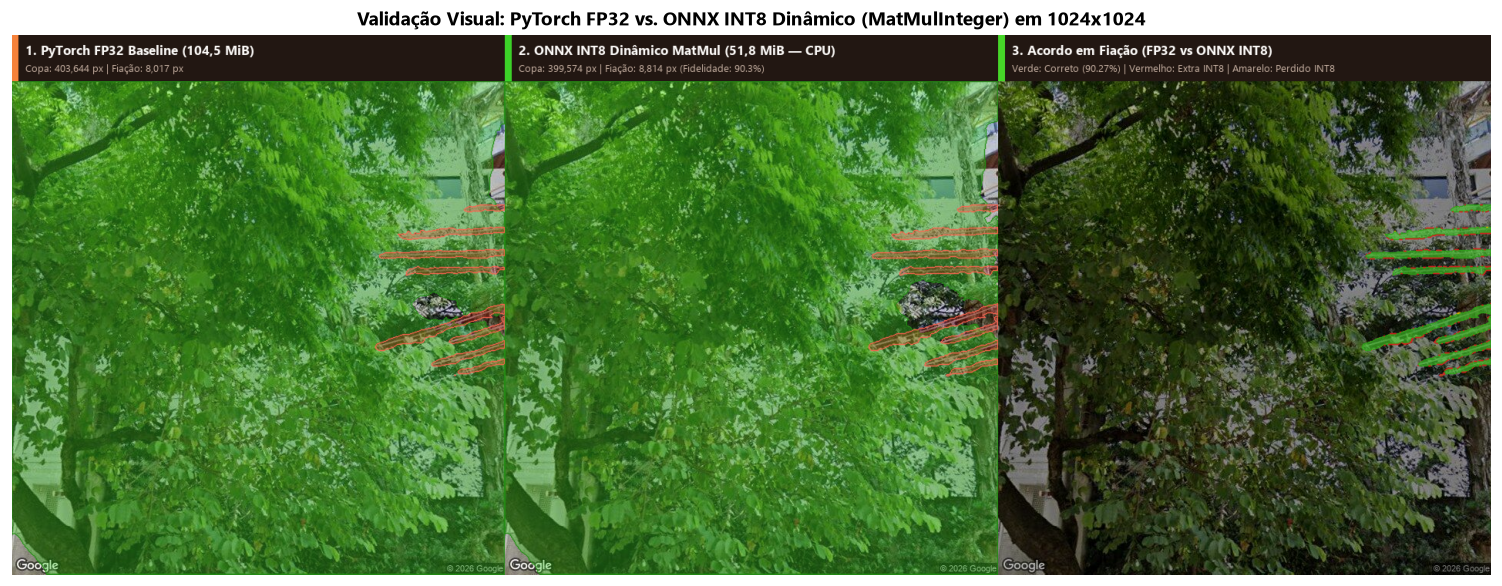

In [4]:
onnx_path = MODELS_DIR / "segformer_v3_int8_dyn_matmul.onnx"
pt_path = MODELS_DIR / "arborgrid_segformer_b2_1024_v3_gold.pt"

ort_sess = load_onnx_session(onnx_path)
pt_model = load_segformer_weights(pt_path, DEVICE)

test_stem = "tree_1001772_center_front_h234"
img_test = cv2.imread(str(WS_DIR / "pacote_1" / f"{test_stem}.jpg"))

t0 = time.perf_counter()
pt_t, pt_w = infer_masks(pt_model, img_test, device=DEVICE, res=1024)
dt_pt = (time.perf_counter() - t0) * 1000.0

t0 = time.perf_counter()
ox_t, ox_w = infer_masks(ort_sess, img_test, res=1024)
dt_ox = (time.perf_counter() - t0) * 1000.0

inter_w = int(np.logical_and(pt_w > 0, ox_w > 0).sum())
union_w = int(np.logical_or(pt_w > 0, ox_w > 0).sum())
iou_fidelidade_w = (inter_w / union_w * 100.0) if union_w > 0 else 100.0

inter_t = int(np.logical_and(pt_t > 0, ox_t > 0).sum())
union_t = int(np.logical_or(pt_t > 0, ox_t > 0).sum())
iou_fidelidade_t = (inter_t / union_t * 100.0) if union_t > 0 else 100.0

print(f"Fidelidade ONNX INT8 vs PyTorch FP32 na amostra #{test_stem}:")
print(f"  -> IoU Copa Arbórea : {iou_fidelidade_t:.2f}% | IoU Fiação Aérea: {iou_fidelidade_w:.2f}%")
print(f"  -> Tempo PyTorch ({DEVICE.type.upper()}): {dt_pt:.1f} ms | Tempo ONNX INT8 (CPU): {dt_ox:.1f} ms")

comp_panel = np.hstack([
    stamp_header(
        render_overlay(img_test, pt_t, pt_w),
        "1. PyTorch FP32 Baseline (104,5 MiB)",
        f"Copa: {int(pt_t.sum()):,} px | Fiação: {int(pt_w.sum()):,} px",
        (59, 130, 246),
    ),
    stamp_header(
        render_overlay(img_test, ox_t, ox_w),
        "2. ONNX INT8 Dinâmico MatMul (51,8 MiB — CPU)",
        f"Copa: {int(ox_t.sum()):,} px | Fiação: {int(ox_w.sum()):,} px (Fidelidade: {iou_fidelidade_w:.1f}%)",
        (40, 210, 60),
    ),
    stamp_header(
        render_diff_panel(img_test, None, pt_w, None, ox_w, alpha=0.58, wire_only=True),
        "3. Acordo em Fiação (FP32 vs ONNX INT8)",
        f"Verde: Correto ({iou_fidelidade_w:.2f}%) | Vermelho: Extra INT8 | Amarelo: Perdido INT8",
        (40, 215, 70),
    ),
])

plt.figure(figsize=(15, 5.2))
plt.imshow(cv2.cvtColor(comp_panel, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.title("Validação Visual: PyTorch FP32 vs. ONNX INT8 Dinâmico (MatMulInteger) em 1024x1024", fontweight="bold")
plt.tight_layout()
plt.show()